## **Environment Setup**

In [ ]:
# Core
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# ML
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# XAI
import shap

# Deep Learning
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.optimizers import Adam

# Performance
import warnings
warnings.filterwarnings("ignore")


## **1 — Dataset Loading (No Download, Reduced Memory)**

In [ ]:
# Install kagglehub if not installed
!pip install kagglehub

import kagglehub
import os
import pandas as pd

# Download dataset (no credentials, no manual download)
path = kagglehub.dataset_download(
    "whenamancodes/flight-delay-prediction"
)

# Correct filename
csv_file = os.path.join(path, "flight_data_2018_to_2022.csv")

# EXACT column names from dataset
use_cols = [
    "Year",
    "Month",
    "DayOfWeek",
    "Marketing_Airline_Network",
    "Origin",
    "Dest",
    "CRSDepTime",
    "DepDelayMinutes",
    "ArrDelayMinutes",
    "WeatherDelay",
    "NASDelay",
    "Cancelled",
    "Distance"
]

# Memory-efficient dtypes
dtypes = {
    "Year": "int16",
    "Month": "int8",
    "DayOfWeek": "int8",
    "Marketing_Airline_Network": "category",
    "Origin": "category",
    "Dest": "category",
    "Cancelled": "int8",
    "Distance": "int16"
}

# Load dataframe (no column mismatch, reduced size)
df = pd.read_csv(
    csv_file,
    usecols=use_cols,
    dtype=dtypes,
    low_memory=True
)

df.head()


Using Colab cache for faster access to the 'flight-delay-prediction' dataset.


,Year,Month,DayOfWeek,Marketing_Airline_Network,Origin,Dest,CRSDepTime,DepDelayMinutes,ArrDelayMinutes,Cancelled,Distance,WeatherDelay,NASDelay
0,2022,1,4,DL,FLL,LGA,1126,NaN,NaN,1,1076,NaN,NaN
1,2022,1,4,DL,ATL,FLL,1631,0.0,0.0,0,581,NaN,NaN
2,2022,1,4,DL,FLL,ATL,1931,0.0,0.0,0,581,NaN,NaN
3,2022,1,4,DL,FLL,RDU,1024,0.0,0.0,0,680,NaN,NaN
4,2022,1,4,DL,ATL,JAN,1117,0.0,0.0,0,341,NaN,NaN


## **2 — Initial Data Exploration**

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 563737 entries, 0 to 563736
Data columns (total 13 columns):
 #   Column                     Non-Null Count   Dtype   
---  ------                     --------------   -----   
 0   Year                       563737 non-null  int16   
 1   Month                      563737 non-null  int8    
 2   DayOfWeek                  563737 non-null  int8    
 3   Marketing_Airline_Network  563737 non-null  category
 4   Origin                     563737 non-null  category
 5   Dest                       563737 non-null  category
 6   CRSDepTime                 563737 non-null  int64   
 7   DepDelayMinutes            528452 non-null  float64 
 8   ArrDelayMinutes            526894 non-null  float64 
 9   Cancelled                  563737 non-null  int8    
 10  Distance                   563737 non-null  int16   
 11  WeatherDelay               102515 non-null  float64 
 12  NASDelay                   102515 non-null  float64 
dtypes: category(3)

In [ ]:
df.isna().mean().sort_values(ascending=False)


,0
WeatherDelay,0.818151
NASDelay,0.818151
ArrDelayMinutes,0.065355
DepDelayMinutes,0.062591
Year,0.000000
Origin,0.000000
Marketing_Airline_Network,0.000000
DayOfWeek,0.000000
Month,0.000000
Dest,0.000000


In [ ]:
df.describe()


,Year,Month,DayOfWeek,CRSDepTime,DepDelayMinutes,ArrDelayMinutes,Cancelled,Distance,WeatherDelay,NASDelay
count,563737.0,563737.0,563737.000000,563737.000000,528452.000000,526894.000000,563737.000000,563737.000000,102515.000000,102515.000000
mean,2022.0,1.0,4.044444,1325.183437,14.620140,14.354921,0.063269,799.278985,4.152797,10.261825
std,0.0,0.0,2.086369,481.634370,49.487456,49.082731,0.243446,587.348755,32.425010,24.147807
min,2022.0,1.0,1.000000,1.000000,0.000000,0.000000,0.000000,31.000000,0.000000,0.000000
25%,2022.0,1.0,2.000000,918.000000,0.000000,0.000000,0.000000,369.000000,0.000000,0.000000
50%,2022.0,1.0,4.000000,1320.000000,0.000000,0.000000,0.000000,650.000000,0.000000,0.000000
75%,2022.0,1.0,6.000000,1726.000000,8.000000,7.000000,0.000000,1042.000000,0.000000,15.000000
max,2022.0,1.0,7.000000,2359.000000,2512.000000,2536.000000,1.000000,5095.000000,1665.000000,1294.000000


## **3 — Data Cleaning & Feature Engineering**

In [ ]:
# Fill delay-related NaNs with 0 (no delay)
delay_cols = ["DepDelayMinutes", "ArrDelayMinutes", "WeatherDelay", "NASDelay"]
df[delay_cols] = df[delay_cols].fillna(0)

df.head()


,Year,Month,DayOfWeek,Marketing_Airline_Network,Origin,Dest,CRSDepTime,DepDelayMinutes,ArrDelayMinutes,Cancelled,Distance,WeatherDelay,NASDelay
0,2022,1,4,DL,FLL,LGA,1126,0.0,0.0,1,1076,0.0,0.0
1,2022,1,4,DL,ATL,FLL,1631,0.0,0.0,0,581,0.0,0.0
2,2022,1,4,DL,FLL,ATL,1931,0.0,0.0,0,581,0.0,0.0
3,2022,1,4,DL,FLL,RDU,1024,0.0,0.0,0,680,0.0,0.0
4,2022,1,4,DL,ATL,JAN,1117,0.0,0.0,0,341,0.0,0.0


In [ ]:
# Create binary delay target (15+ mins arrival delay)
df["Delayed"] = (df["ArrDelayMinutes"] >= 15).astype(int)

df.head()

,Year,Month,DayOfWeek,Marketing_Airline_Network,Origin,Dest,CRSDepTime,DepDelayMinutes,ArrDelayMinutes,Cancelled,Distance,WeatherDelay,NASDelay,Delayed
0,2022,1,4,DL,FLL,LGA,1126,0.0,0.0,1,1076,0.0,0.0,0
1,2022,1,4,DL,ATL,FLL,1631,0.0,0.0,0,581,0.0,0.0,0
2,2022,1,4,DL,FLL,ATL,1931,0.0,0.0,0,581,0.0,0.0,0
3,2022,1,4,DL,FLL,RDU,1024,0.0,0.0,0,680,0.0,0.0,0
4,2022,1,4,DL,ATL,JAN,1117,0.0,0.0,0,341,0.0,0.0,0


In [ ]:
# Convert CRSDepTime to hour
df["DepHour"] = df["CRSDepTime"] // 100
df.head()

,Year,Month,DayOfWeek,Marketing_Airline_Network,Origin,Dest,CRSDepTime,DepDelayMinutes,ArrDelayMinutes,Cancelled,Distance,WeatherDelay,NASDelay,Delayed,DepHour
0,2022,1,4,DL,FLL,LGA,1126,0.0,0.0,1,1076,0.0,0.0,0,11
1,2022,1,4,DL,ATL,FLL,1631,0.0,0.0,0,581,0.0,0.0,0,16
2,2022,1,4,DL,FLL,ATL,1931,0.0,0.0,0,581,0.0,0.0,0,19
3,2022,1,4,DL,FLL,RDU,1024,0.0,0.0,0,680,0.0,0.0,0,10
4,2022,1,4,DL,ATL,JAN,1117,0.0,0.0,0,341,0.0,0.0,0,11


In [ ]:
# Drop original CRSDepTime
df.drop(columns=["CRSDepTime"], inplace=True)
df.head()


KeyError: "['CRSDepTime'] not found in axis"

## **4 — Exploratory Data Analysis**

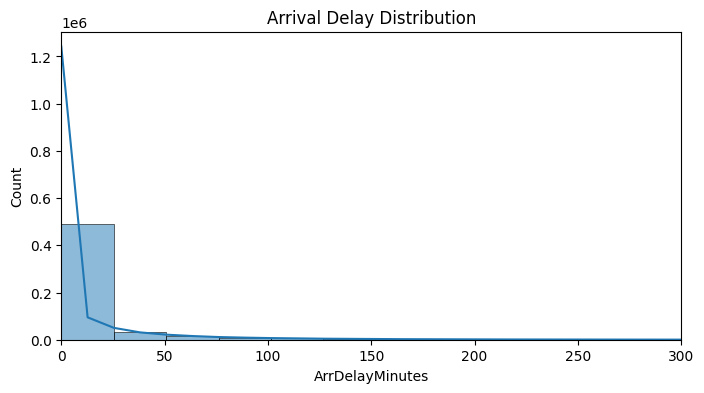

In [ ]:
## Delay Distribution

plt.figure(figsize=(8,4))
sns.histplot(df["ArrDelayMinutes"], bins=100, kde=True)
plt.xlim(0, 300)
plt.title("Arrival Delay Distribution")
plt.show()


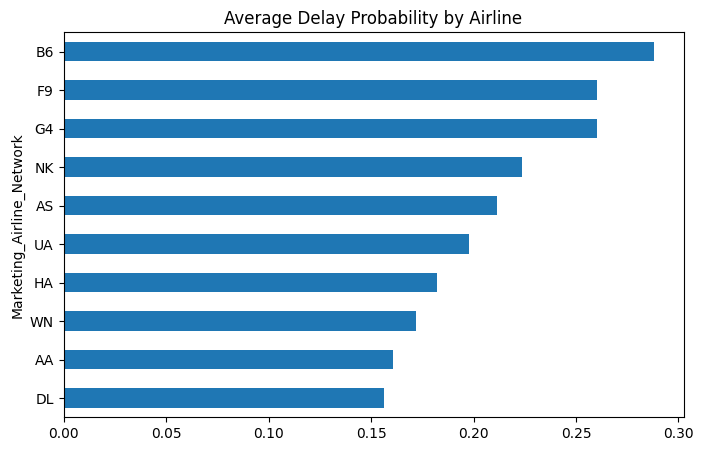

In [ ]:
## Delay Rate by Airline

airline_delay = df.groupby("Marketing_Airline_Network")["Delayed"].mean().sort_values()

airline_delay.plot(kind="barh", figsize=(8,5))
plt.title("Average Delay Probability by Airline")
plt.show()


In [ ]:
## Monthly Delay Pattern (Interactive)

monthly = df.groupby("Month")["ArrDelayMinutes"].mean().reset_index()

px.line(
    monthly,
    x="Month",
    y="ArrDelayMinutes",
    markers=True,
    title="Average Arrival Delay by Month"
)


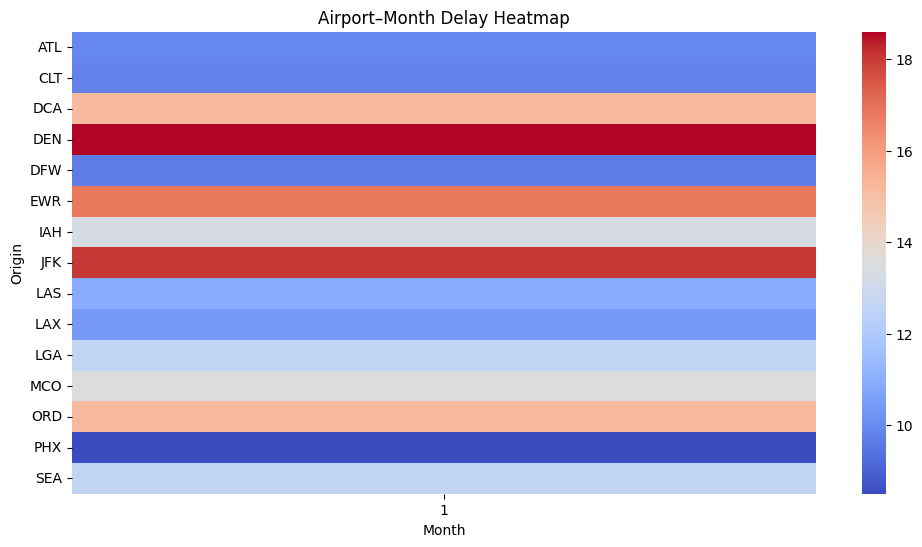

In [ ]:
## Origin Airport Heatmap

top_origins = df["Origin"].value_counts().head(15).index
heatmap_df = df[df["Origin"].isin(top_origins)]

pivot = heatmap_df.pivot_table(
    values="ArrDelayMinutes",
    index="Origin",
    columns="Month",
    aggfunc="mean"
)

plt.figure(figsize=(12,6))
sns.heatmap(pivot, cmap="coolwarm")
plt.title("Airport–Month Delay Heatmap")
plt.show()


## **5 — Train/Test Split & Preprocessing**

In [ ]:
X = df.drop(columns=["Delayed"])
y = df["Delayed"]

cat_cols = ["Marketing_Airline_Network", "Origin", "Dest"]
num_cols = X.select_dtypes(include=["int", "float"]).columns.tolist()


preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)


## **6 — Traditional ML Models**

In [ ]:
## Helper Function (Metrics + Plots)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix
)

def evaluate_model(model, X_test, y_test, model_name):
    # Predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    print(f"\n {model_name} Performance")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-score  : {f1:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(4,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{model_name} – Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)

    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    plt.plot([0,1], [0,1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} – ROC Curve")
    plt.legend()
    plt.show()




📌 Logistic Regression Performance
Accuracy  : 0.9989
Precision : 0.9996
Recall    : 0.9940
F1-score  : 0.9968
ROC-AUC   : 1.0000


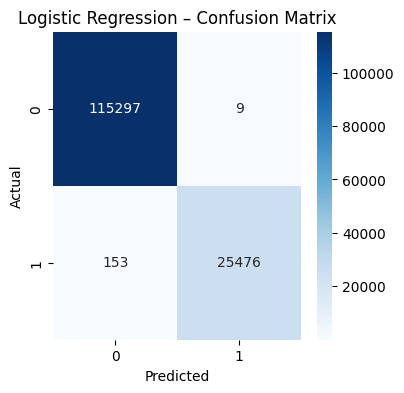

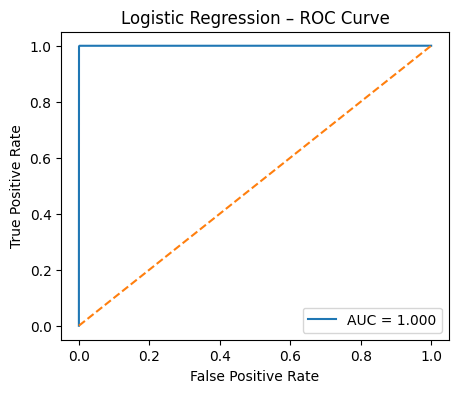

In [ ]:
## Logistic Regression (Baseline Model)

log_model = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=500))
])

log_model.fit(X_train, y_train)

evaluate_model(
    log_model,
    X_test,
    y_test,
    "Logistic Regression"
)



📌 Random Forest Performance
Accuracy  : 0.9897
Precision : 1.0000
Recall    : 0.9431
F1-score  : 0.9707
ROC-AUC   : 1.0000


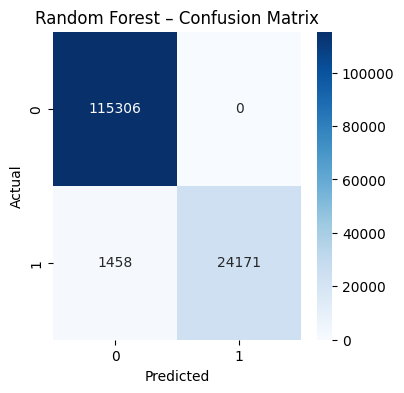

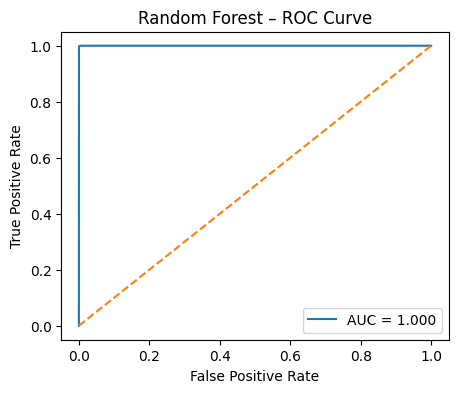

In [ ]:
## Random Forest Classifier

rf_model = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

evaluate_model(
    rf_model,
    X_test,
    y_test,
    "Random Forest"
)



📌 Gradient Boosting Performance
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-score  : 1.0000
ROC-AUC   : 1.0000


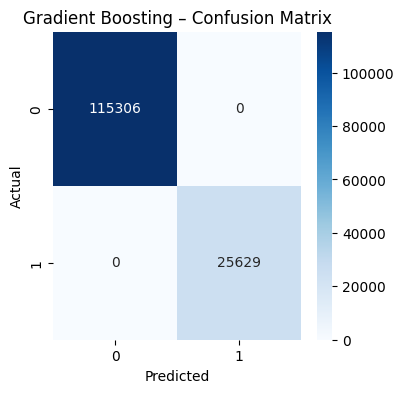

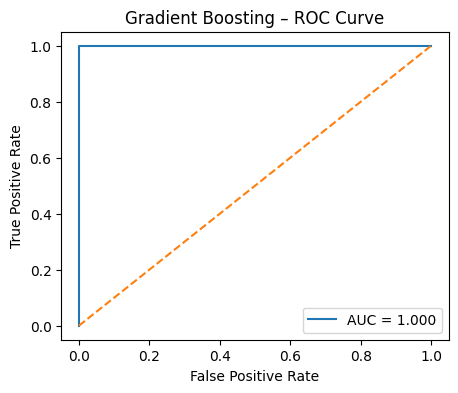

In [ ]:
## Gradient Boosting Classifier

gb_model = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

gb_model.fit(X_train, y_train)

evaluate_model(
    gb_model,
    X_test,
    y_test,
    "Gradient Boosting"
)


In [ ]:
# Dictionary to store model metrics
model_metrics = {}

def collect_metrics(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    model_metrics[model_name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }


# Collect metrics for each model
collect_metrics(log_model, X_test, y_test, "Logistic Regression")
collect_metrics(rf_model, X_test, y_test, "Random Forest")
collect_metrics(gb_model, X_test, y_test, "Gradient Boosting")


In [ ]:
## Metrics Comparison Table

metrics_df = pd.DataFrame(model_metrics).T
metrics_df

# Rounded version for reporting
metrics_df.round(4)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.9989,0.9996,0.9940,0.9968,1.0
Random Forest,0.9897,1.0000,0.9431,0.9707,1.0
Gradient Boosting,1.0000,1.0000,1.0000,1.0000,1.0


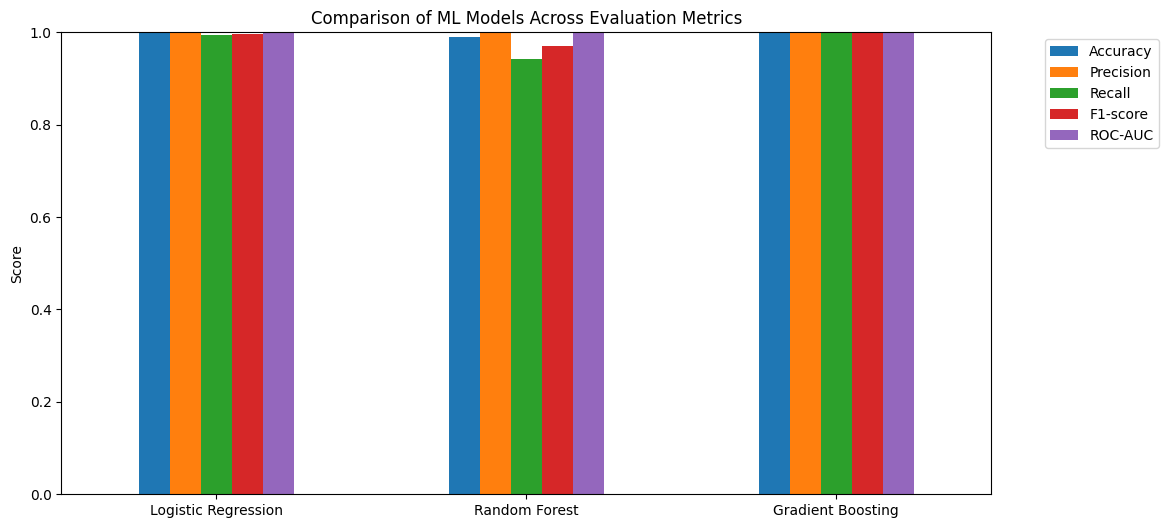

In [ ]:
## Bar Chart Comparison of Metrics

metrics_df.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Comparison of ML Models Across Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()


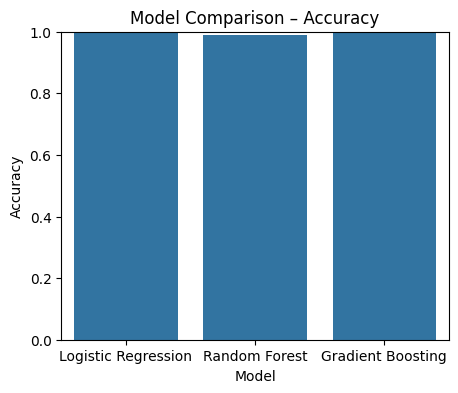

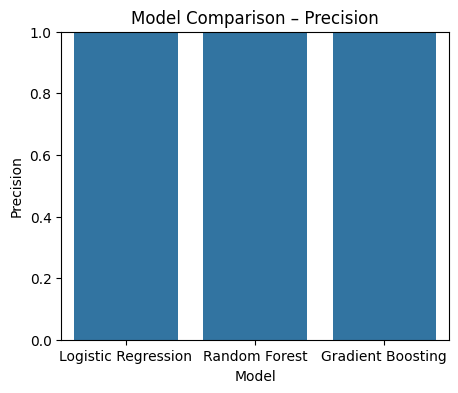

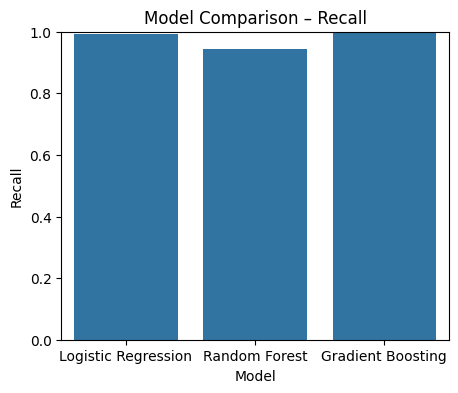

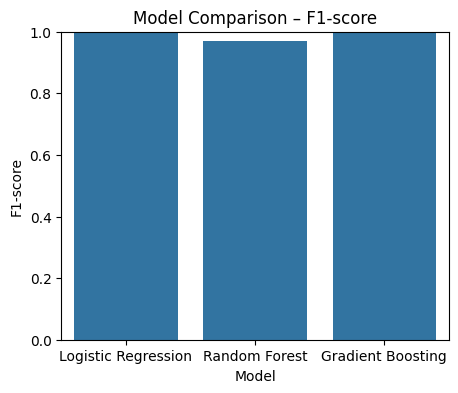

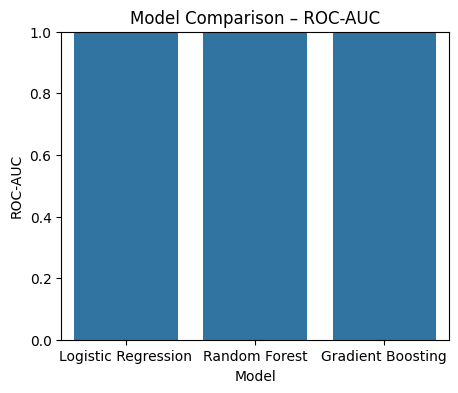

In [ ]:
## Individual Metric Comparison Plots

for metric in metrics_df.columns:
    plt.figure(figsize=(5,4))
    sns.barplot(
        x=metrics_df.index,
        y=metrics_df[metric]
    )
    plt.title(f"Model Comparison – {metric}")
    plt.ylim(0, 1)
    plt.ylabel(metric)
    plt.xlabel("Model")
    plt.show()


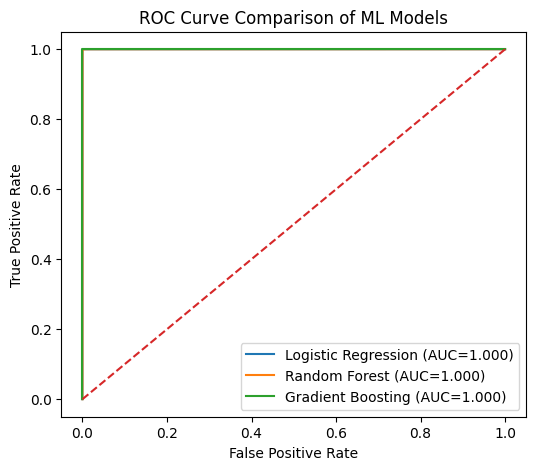

In [ ]:
## Combined ROC Curve Comparison

plt.figure(figsize=(6,5))

for model, name in zip(
    [log_model, rf_model, gb_model],
    ["Logistic Regression", "Random Forest", "Gradient Boosting"]
):
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_score:.3f})")

plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of ML Models")
plt.legend()
plt.show()


## **Explainable AI with SHAP**

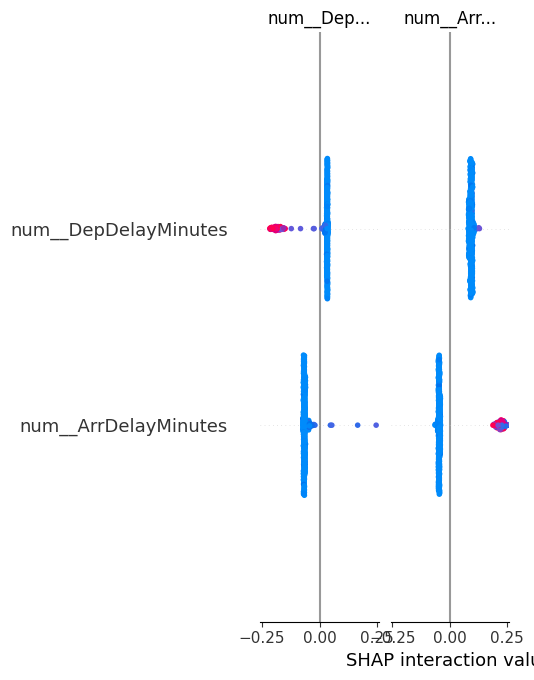

In [ ]:



import shap


rf = rf_model.named_steps["model"]
prep = rf_model.named_steps["prep"]


X_transformed = prep.transform(X_train)


if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()


X_sample = X_transformed[:500]


feature_names = prep.get_feature_names_out()

# Create SHAP explainer
explainer = shap.TreeExplainer(rf)

# Compute SHAP values
shap_values = explainer.shap_values(X_sample)


if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values

# Ensure final shape consistency
assert shap_values_to_plot.shape[1] == X_sample.shape[1], \
    "SHAP values and feature matrix still misaligned"

# Plot
shap.summary_plot(
    shap_values_to_plot,
    X_sample,
    feature_names=feature_names,
    show=True
)


## **Deep Learning (LSTM Delay Prediction)**

In [ ]:
X_dl = df[num_cols]
y_dl = df["ArrDelayMinutes"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_dl)

X_lstm = X_scaled.reshape(X_scaled.shape[0], 1, X_scaled.shape[1])

model = Sequential([
    LSTM(64, input_shape=(1, X_lstm.shape[2])),
    Dropout(0.3),
    Dense(1)
])

model.compile(
    optimizer=Adam(0.001),
    loss="mse"
)

model.fit(
    X_lstm, y_dl,
    epochs=10,
    batch_size=512,
    validation_split=0.2
)


Epoch 1/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 2069.9761 - val_loss: 2105.6306
Epoch 2/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - loss: 1425.4060 - val_loss: 1681.1438
Epoch 3/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - loss: 1086.6266 - val_loss: 1414.2327
Epoch 4/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - loss: 961.5118 - val_loss: 1220.3586
Epoch 5/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - loss: 861.5526 - val_loss: 1069.1932
Epoch 6/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 731.3815 - val_loss: 946.1889
Epoch 7/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 722.0131 - val_loss: 845.6656
Epoch 8/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 677.2769 - val_loss: 761.3133
Epoch 9/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 537.7806 - val_loss: 688.3658
Epoch 10/10
881/881 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 528.7988 - val_loss: 623.7810


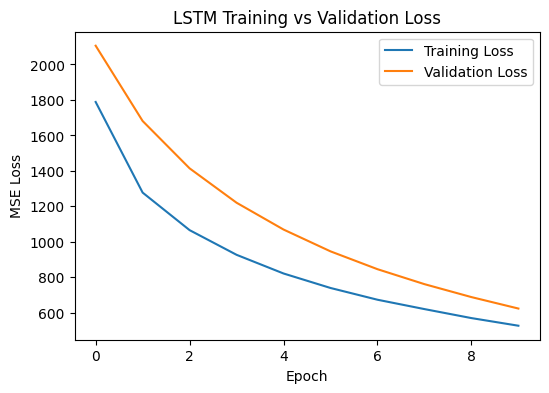

In [ ]:
## Training & Validation Loss Curve

# Capture training history
history = model.history.history

plt.figure(figsize=(6,4))
plt.plot(history["loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.show()


17617/17617 ━━━━━━━━━━━━━━━━━━━━ 31s 2ms/step


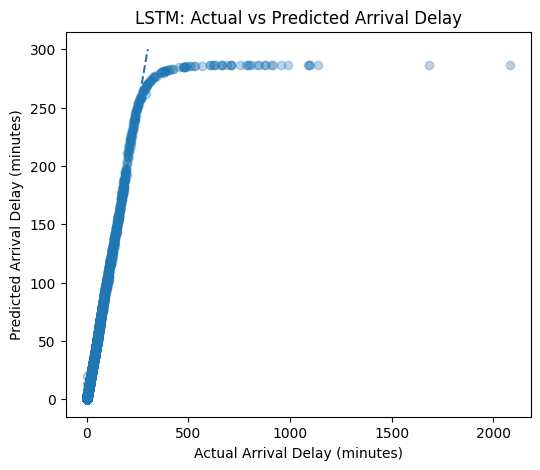

In [ ]:
## Actual vs Predicted Delay (Scatter Plot)

# Generate predictions
y_pred_dl = model.predict(X_lstm).flatten()

# Sample for plotting (large dataset safe)
sample_idx = np.random.choice(len(y_pred_dl), size=20000, replace=False)

plt.figure(figsize=(6,5))
plt.scatter(
    y_dl.iloc[sample_idx],
    y_pred_dl[sample_idx],
    alpha=0.3
)
plt.xlabel("Actual Arrival Delay (minutes)")
plt.ylabel("Predicted Arrival Delay (minutes)")
plt.title("LSTM: Actual vs Predicted Arrival Delay")
plt.plot([0,300], [0,300], linestyle="--")
plt.show()


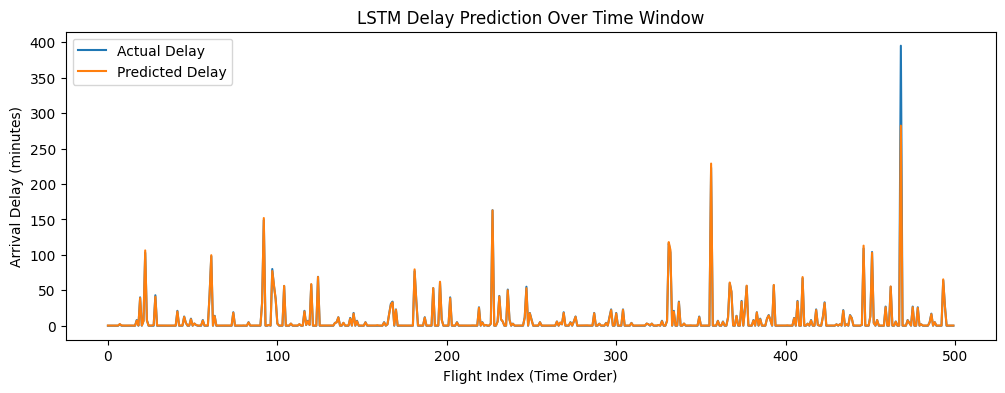

In [ ]:
# Time-Ordered Prediction
window = 500

plt.figure(figsize=(12,4))
plt.plot(y_dl.iloc[:window].values, label="Actual Delay")
plt.plot(y_pred_dl[:window], label="Predicted Delay")
plt.xlabel("Flight Index (Time Order)")
plt.ylabel("Arrival Delay (minutes)")
plt.title("LSTM Delay Prediction Over Time Window")
plt.legend()
plt.show()


In [ ]:
## Regression Performance Metrics

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_dl, y_pred_dl)
rmse = np.sqrt(mean_squared_error(y_dl, y_pred_dl))
r2 = r2_score(y_dl, y_pred_dl)

print("LSTM Regression Metrics")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")


LSTM Regression Metrics
MAE  : 1.42
RMSE : 22.88
R²   : 0.7688


## **Interactive Dashboard (Plotly)**

In [ ]:
px.scatter(
    df.sample(20000),
    x="Distance",
    y="ArrDelayMinutes",
    color="Marketing_Airline_Network",
    title="Distance vs Arrival Delay (Interactive)"
)


In [ ]:
## Airline-Wise Delay Distribution (Box Plot)

fig = px.box(
    df.sample(200000),
    x="Marketing_Airline_Network",
    y="ArrDelayMinutes",
    title="Arrival Delay Distribution by Airline",
    labels={"Marketing_Airline_Network": "Airline"}
)

fig.update_yaxes(range=[-50, 300])
fig.show()


In [ ]:
## Distance vs Delay (Interactive Scatter)

fig = px.scatter(
    df.sample(150000),
    x="Distance",
    y="ArrDelayMinutes",
    color="Cancelled",
    opacity=0.5,
    title="Flight Distance vs Arrival Delay",
    labels={"ArrDelayMinutes": "Arrival Delay (minutes)"}
)

fig.show()


In [ ]:
## Delay Probability by Departure Hour

hourly_delay = (
    df.groupby("DepHour")["Delayed"]
    .mean()
    .reset_index()
)

fig = px.bar(
    hourly_delay,
    x="DepHour",
    y="Delayed",
    title="Probability of Delay by Departure Hour",
    labels={"Delayed": "Delay Probability"}
)

fig.show()
